<a href="https://colab.research.google.com/github/Xa-Sierra/deep_CONIEEM/blob/main/Deep_CONIEEM_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Taller: Introducción a Deep Learning para Ingeniería con PyTorch
## Día 1 — Bloque 1: Entorno, Tensores y Mecánica Interna (autograd)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/<TU_USUARIO>/<TU_REPOSITORIO>/blob/main/Dia1_Bloque1_Tensores_y_Autograd.ipynb)

---
### Objetivos de este bloque:
1. Verificar y configurar el acelerador de hardware (GPU) en Google Colab.
2. Comprender el concepto de **Tensor** mediante analogías con señales, arreglos de sensores y circuitos.
3. Dominar las operaciones esenciales con tensores y su interoperabilidad con `NumPy`.
4. Descubrir la mecánica del motor de autodiferenciación (`torch.autograd`) y cómo calcula gradientes automáticamente.

In [1]:
# 1. Verificación del entorno y aceleración por GPU
import torch
import numpy as np

print(f"Versión de PyTorch: {torch.__version__}")

# Comprobación de disponibilidad de GPU (NVIDIA CUDA)
if torch.cuda.is_available():
    device = torch.device("cuda")
    gpu_name = torch.cuda.get_device_name(0)
    print(f"[OK] Acelerador activo: {gpu_name}")
else:
    device = torch.device("cpu")
    print("[AVISO] GPU no detectada. Trabajando en CPU.")
    print("Recuerda activar la GPU en: Entorno de ejecución > Cambiar tipo de entorno de ejecución > T4 GPU")

Versión de PyTorch: 2.11.0+cu128
[OK] Acelerador activo: Tesla T4


---
### 1. ¿Qué es un Tensor? (Perspectiva de Ingeniería)

En ingeniería estamos acostumbrados a trabajar con arreglos numéricos para representar magnitudes físicas:
* **Escalar (Tensor 0D):** Una medición puntual (ej. $V = 5.0\text{ V}$, $T = 25.4\ ^\circ\text{C}$).
* **Vector (Tensor 1D):** Una señal temporal muestreada (ej. una traza de osciloscopio o un canal de ECG: $[v_0, v_1, \dots, v_{N-1}]$).
* **Matriz (Tensor 2D):** Una matriz de impedancias, un mapa térmico o lecturas de un arreglo de sensores ($M \times N$).
* **Tensor 3D/4D:** Imágenes médicas/microscopía (Canales $\times$ Alto $\times$ Ancho) o lotes de mediciones (Batch $\times$ Muestras $\times$ Canales).

La gran ventaja de un tensor de PyTorch frente a un `np.ndarray` es que **puede alojarse en memoria GPU** y **rastrea operaciones para calcular derivadas automáticamente**.

In [2]:
# 2. Creación básica de tensores

# Desde listas nativas de Python (ej. mediciones de corriente en mA)
corrientes = torch.tensor([12.5, 14.1, 11.8, 15.0], dtype=torch.float32)
print("Vector 1D (Señal temporal):", corrientes)
print(f"Forma (shape): {corrientes.shape} | Tipo: {corrientes.dtype}\n")

# Matriz 2D: Inicialización de ceros, unos y valores aleatorios (ruido térmico/gaussiano)
matriz_ceros = torch.zeros((3, 4))                     # Matriz 3x4 vacía
ruido_sensor = torch.randn((4, 4), dtype=torch.float32) # Ruido con distribución normal N(0, 1)

print("Matriz de ruido (4x4):\n", ruido_sensor)

Vector 1D (Señal temporal): tensor([12.5000, 14.1000, 11.8000, 15.0000])
Forma (shape): torch.Size([4]) | Tipo: torch.float32

Matriz de ruido (4x4):
 tensor([[-2.1830,  0.9904,  0.3453,  0.7713],
        [ 2.0948, -0.0198, -0.6876, -0.2298],
        [-2.2379, -1.1012,  0.2323, -1.6477],
        [-0.0286, -0.6292, -1.6979, -2.0457]])


In [3]:
# 3. Interoperabilidad NumPy <-> PyTorch y manejo de dispositivos

# Creación de señal senoidal en NumPy
t = np.linspace(0, 1, 100)
senal_np = np.sin(2 * np.pi * 5 * t)  # Señal de 5 Hz

# Conversión de NumPy a PyTorch (comparte memoria en CPU)
senal_torch = torch.from_numpy(senal_np).float()

print(f"Tipo origen: {type(senal_np)} -> Tipo destino: {type(senal_torch)}")

# Mover el tensor a la GPU si está disponible
senal_gpu = senal_torch.to(device)
print(f"El tensor ahora reside en: {senal_gpu.device}")

Tipo origen: <class 'numpy.ndarray'> -> Tipo destino: <class 'torch.Tensor'>
El tensor ahora reside en: cuda:0


---
### 2. El Corazón del Deep Learning: Autodiferenciación (`torch.autograd`)

Para que una red neuronal aprenda, necesitamos ajustar sus parámetros (pesos y sesgos) en dirección opuesta al gradiente del error:
$$\theta \leftarrow \theta - \eta \nabla_\theta \mathcal{L}$$

Calcular derivadas parciales a mano para miles o millones de parámetros es inviable. PyTorch construye dinámicamente un **Grafo Computacional Dirigido (DAG)** durante el pase hacia adelante (*forward pass*).

Si activamos `requires_grad=True` en una variable, cada operación que involucre dicha variable registrará su función derivada. Al invocar `.backward()`, se aplica la regla de la cadena de forma automática.

In [4]:
# 4. Cálculo automático de gradientes con torch.autograd

# Definimos una variable de entrada con seguimiento de gradiente
# Ejemplo: consideremos la función de costo f(x) = 3*x^2 + 2*x + 1
x = torch.tensor(2.0, requires_grad=True)

# Evaluación de la función (Forward pass)
y = 3 * (x ** 2) + 2 * x + 1
print(f"Para x = {x.item()}, y = {y.item()}")

# Cálculo de la derivada df/dx evaluada en x = 2
# Analíticamente: f'(x) = 6*x + 2 -> f'(2) = 14.0
y.backward()

# Inspeccionamos el gradiente acumulado en x
print(f"Gradiente dy/dx calculado por autograd: {x.grad.item()}")

Para x = 2.0, y = 17.0
Gradiente dy/dx calculado por autograd: 14.0


---
### 3. Caso Práctico de Ingeniería: Calibración de Sensor mediante Descenso de Gradiente

Supongamos que tenemos un sensor de temperatura piezoeléctrico/resistivo cuya respuesta ideal es lineal:
$$V_{\text{out}} = w \cdot T + b$$
donde:
* $T$: Temperatura de entrada en $^\circ\text{C}$
* $w$: Sensibilidad nominal del sensor ($V/^\circ\text{C}$)
* $b$: Tensión de offset ($V$)

Ajustaremos $w$ y $b$ minimizando el Error Cuadrático Medio (MSE) usando únicamente tensores y `autograd`, sin usar aún módulos de alto nivel.

In [5]:
# 5. Descenso de gradiente explícito paso a paso
import matplotlib.pyplot as plt

# Generamos datos sintéticos experimentales del sensor
torch.manual_seed(42)
T = torch.linspace(0, 100, 20).unsqueeze(1)               # 20 lecturas de 0 a 100 °C
# Parámetros reales ocultos: w = 0.05 V/°C, b = 0.5 V + ruido gaussiano
V_real = 0.05 * T + 0.5 + torch.randn_like(T) * 0.15

# Inicializamos parámetros a estimar con valores aleatorios
w = torch.randn(1, requires_grad=True)
b = torch.zeros(1, requires_grad=True)

# Hiperparámetros de optimización
lr = 0.0001  # Tasa de aprendizaje
epocas = 500

historial_perdida = []

for epoca in range(epocas):
    # 1. Forward pass: estimación del modelo
    V_pred = w * T + b

    # 2. Función de pérdida (MSE: Mean Squared Error)
    loss = torch.mean((V_pred - V_real) ** 2)
    historial_perdida.append(loss.item())

    # 3. Backward pass: autograd calcula d(loss)/dw y d(loss)/db
    loss.backward()

    # 4. Actualización manual de parámetros (sin rastrear gradiente de este paso)
    with torch.no_grad():
        w -= lr * w.grad
        b -= lr * b.grad

        # IMPORTANTE: Limpiar los gradientes para la siguiente época
        w.grad.zero_()
        b.grad.zero_()

print(f"Parámetros calibrados: w = {w.item():.4f} V/°C (Esperado ~0.05), b = {b.item():.4f} V (Esperado ~0.5)")

Parámetros calibrados: w = 0.0570 V/°C (Esperado ~0.05), b = 0.0277 V (Esperado ~0.5)


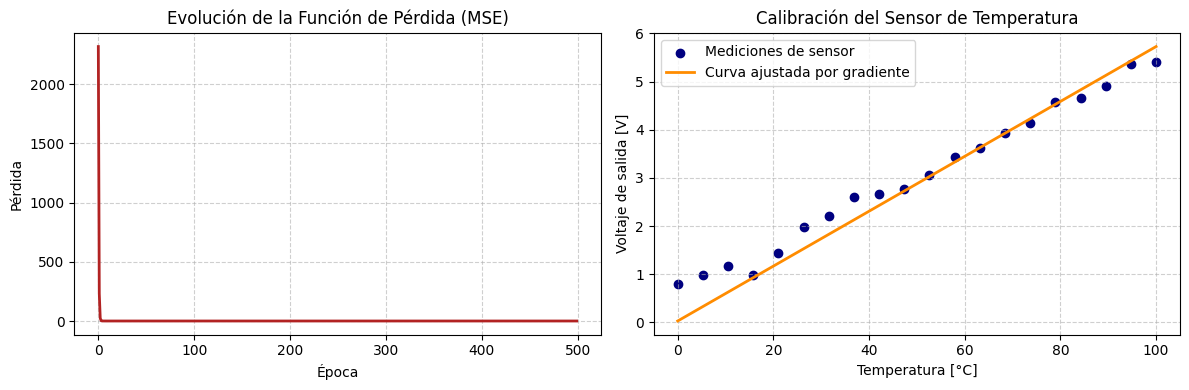

In [6]:
# 6. Gráfica de convergencia y ajuste lineal
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

# Curva de pérdida
ax[0].plot(historial_perdida, color='firebrick', lw=2)
ax[0].set_title("Evolución de la Función de Pérdida (MSE)")
ax[0].set_xlabel("Época")
ax[0].set_ylabel("Pérdida")
ax[0].grid(True, linestyle="--", alpha=0.6)

# Calibración del sensor
ax[1].scatter(T.numpy(), V_real.numpy(), color='navy', label='Mediciones de sensor')
ax[1].plot(T.numpy(), (w.detach() * T + b.detach()).numpy(), color='darkorange', lw=2, label='Curva ajustada por gradiente')
ax[1].set_title("Calibración del Sensor de Temperatura")
ax[1].set_xlabel("Temperatura [°C]")
ax[1].set_ylabel("Voltaje de salida [V]")
ax[1].legend()
ax[1].grid(True, linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()

---
### 🛠️ Mini-Reto del Bloque 1 (10 minutos)
**Actividad para los asistentes:**
1. Modifica la tasa de aprendizaje `lr` a un valor más alto (ej. `0.01` o `0.1`). ¿Qué le ocurre al valor de `loss`? ¿Por qué diverge?
2. Añade un término cuadrático a la simulación del sensor ($V_{\text{real}} = a \cdot T^2 + w \cdot T + b$) e incorpora el parámetro entrenable $a$ al bucle de optimización.